In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# 1. Đọc dữ liệu
df = pd.read_csv("dataset.csv", low_memory=False)
print(f"Kích thước dữ liệu: {df.shape}")

# 2. Bộ hàm tiện ích cho tiêu chí D5 (Quantifying uncertainty)
def cliffs_delta_from_mwu(x, y):
    """Tính Cliff's delta nhanh qua Mann-Whitney U: delta = 2U / (n1*n2) - 1"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    u_stat, p_val = stats.mannwhitneyu(x, y, alternative="two-sided")
    delta = (2.0 * u_stat) / (len(x) * len(y)) - 1.0
    return delta, p_val

def bootstrap_diff_stat(x, y, stat_func=np.median, n_boot=1000, seed=42):
    """Tính chênh lệch thống kê (x - y) và 95% Bootstrap CI"""
    rng = np.random.default_rng(seed)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    
    obs_diff = stat_func(x) - stat_func(y)
    diffs = np.empty(n_boot)
    nx, ny = len(x), len(y)
    for i in range(n_boot):
        bx = x[rng.integers(0, nx, nx)]
        by = y[rng.integers(0, ny, ny)]
        diffs[i] = stat_func(bx) - stat_func(by)
        
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, ci_low, ci_high

def odds_ratio_ci(a_yes, a_no, b_yes, b_no):
    """Tính Odds Ratio giữa nhóm A và nhóm B kèm 95% CI (Haldane-Anscombe correction)"""
    a_y, a_n = a_yes + 0.5, a_no + 0.5
    b_y, b_n = b_yes + 0.5, b_no + 0.5
    or_val = (a_y / a_n) / (b_y / b_n)
    se_log_or = np.sqrt(1/a_y + 1/a_n + 1/b_y + 1/b_n)
    ci_low = np.exp(np.log(or_val) - 1.96 * se_log_or)
    ci_high = np.exp(np.log(or_val) + 1.96 * se_log_or)
    return or_val, ci_low, ci_high

Kích thước dữ liệu: (958524, 45)


**Q1: Hình dạng quỹ đạo có quyết định mức độ nguy hiểm tiềm tàng (`pha / moid`) khi kiểm soát phân loại quỹ đạo (`class`)**

Liệu các tiểu hành tinh có quỹ đạo kéo dài và lệch tâm mạnh hơn có xu hướng tiến gần quỹ đạo Trái Đất hơn (`moid`) và dễ thuộc nhóm nguy hiểm tiềm tàng (`pha`) hơn không, ngay cả khi xét trong cùng một nhóm phân loại quỹ đạo (`class`).

,Class,Inclination,N,Diff_Median_MOID (High-Low),95% CI MOID,Cliffs_Delta,PHA_Odds_Ratio,95% CI OR
0,AMO,High_Inc (>15°),2906,0.0683,"[0.0543, 0.0802]",0.248,1.98,"[1.02, 3.83]"
1,AMO,Low_Inc (<=15°),5550,-0.0097,"[-0.0169, -0.0009]",-0.043,2.04,"[1.28, 3.26]"
2,APO,High_Inc (>15°),3449,0.0536,"[0.0458, 0.0643]",0.309,1.42,"[1.18, 1.70]"
3,APO,Low_Inc (<=15°),9238,0.0030,"[0.0018, 0.0043]",0.085,2.62,"[2.30, 2.99]"
4,ATE,High_Inc (>15°),552,0.0193,"[0.0030, 0.0368]",0.143,1.39,"[0.86, 2.26]"
5,ATE,Low_Inc (<=15°),1177,0.0019,"[-0.0011, 0.0054]",0.077,3.28,"[2.04, 5.26]"
6,MCA,High_Inc (>15°),8613,0.0154,"[0.0106, 0.0215]",0.107,1.00,"[0.02, 50.40]"
7,MCA,Low_Inc (<=15°),9743,-0.1048,"[-0.1093, -0.0992]",-0.500,1.00,"[0.02, 50.40]"


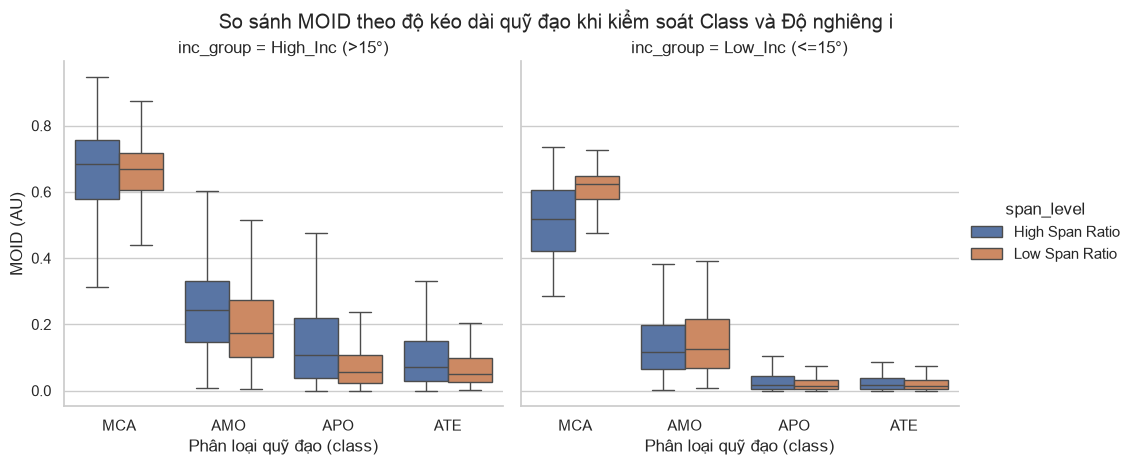

,Scenario,Diff_MOID,95% CI,Cliffs_Delta
0,"Baseline (All, Median cut)",0.0030,"[0.0018, 0.0043]",0.085
1,Strict RMS <= 0.5 (Median cut),0.0037,"[0.0024, 0.0052]",0.110
2,Baseline (Q75 cut),0.0052,"[0.0034, 0.0068]",0.127


In [2]:
# --- D3: Tạo biến dẫn xuất ---
q1_df = df[["class", "a", "q", "ad", "e", "i", "moid", "pha", "rms"]].dropna(subset=["class", "a", "q", "ad", "i", "moid"]).copy()
q1_df = q1_df[q1_df["a"] > 0]

# Tỷ số kéo dài quỹ đạo (Span_Ratio) và Tỷ số cận nhật so với quỹ đạo Trái Đất (1 AU)
q1_df["span_ratio"] = (q1_df["ad"] - q1_df["q"]) / q1_df["a"]
q1_df["q_earth_ratio"] = q1_df["q"] / 1.0
q1_df["is_pha"] = (q1_df["pha"] == "Y").astype(int)

# --- D4: Kiểm soát biến nhiễu (class & độ nghiêng quỹ đạo i) ---
# Tập trung vào các nhóm Near-Earth / Mars-crosser có sự xuất hiện của PHA
target_classes = ["APO", "AMO", "ATE", "MCA"]
q1_sub = q1_df[q1_df["class"].isin(target_classes)].copy()

# Chia tầng độ nghiêng quỹ đạo i thành 2 nhóm: Nghiêng thấp (<= 15 độ) và Nghiêng cao (> 15 độ)
q1_sub["inc_group"] = np.where(q1_sub["i"] <= 15, "Low_Inc (<=15°)", "High_Inc (>15°)")

# --- D5: Định lượng độ bất định trong từng phân tầng ---
results_q1 = []
for (cls, inc_g), grp in q1_sub.groupby(["class", "inc_group"], observed=True):
    if len(grp) < 50:
        continue
    med_span = grp["span_ratio"].median()
    high_span = grp[grp["span_ratio"] >= med_span]
    low_span = grp[grp["span_ratio"] < med_span]
    
    diff_moid, ci_l, ci_h = bootstrap_diff_stat(high_span["moid"], low_span["moid"], np.median, n_boot=1000)
    delta, p_val = cliffs_delta_from_mwu(high_span["moid"], low_span["moid"])
    or_val, or_l, or_h = odds_ratio_ci(
        high_span["is_pha"].sum(), len(high_span) - high_span["is_pha"].sum(),
        low_span["is_pha"].sum(), len(low_span) - low_span["is_pha"].sum()
    )
    results_q1.append({
        "Class": cls, "Inclination": inc_g, "N": len(grp),
        "Diff_Median_MOID (High-Low)": round(diff_moid, 4),
        "95% CI MOID": f"[{ci_l:.4f}, {ci_h:.4f}]",
        "Cliffs_Delta": round(delta, 3),
        "PHA_Odds_Ratio": round(or_val, 2),
        "95% CI OR": f"[{or_l:.2f}, {or_h:.2f}]"
    })

res_q1_df = pd.DataFrame(results_q1)
display(res_q1_df)

# Trực quan hóa D4 + D5
q1_sub["span_level"] = q1_sub.groupby(["class", "inc_group"], observed=True)["span_ratio"].transform(
    lambda s: np.where(s >= s.median(), "High Span Ratio", "Low Span Ratio")
)
g = sns.catplot(
    data=q1_sub, x="class", y="moid", hue="span_level", col="inc_group",
    kind="box", showfliers=False, height=4.5, aspect=1.1
)
g.set_axis_labels("Phân loại quỹ đạo (class)", "MOID (AU)")
plt.suptitle("So sánh MOID theo độ kéo dài quỹ đạo khi kiểm soát Class và Độ nghiêng i", y=1.03)
plt.show()

# --- D6: Kiểm tra tính vững (Robustness check) ---
# Kịch bản A: Chỉ giữ quan trắc quỹ đạo chính xác cao (rms <= 0.5)
# Kịch bản B: Dùng ngưỡng phân vị 75% (Q3) thay vì trung vị cho span_ratio
q1_clean = q1_sub[q1_sub["rms"] <= 0.5]
rob_q1 = []
for scenario, data_s, q_cut in [
    ("Baseline (All, Median cut)", q1_sub, 0.50),
    ("Strict RMS <= 0.5 (Median cut)", q1_clean, 0.50),
    ("Baseline (Q75 cut)", q1_sub, 0.75)
]:
    apo_low_i = data_s[(data_s["class"] == "APO") & (data_s["i"] <= 15)]
    thresh = apo_low_i["span_ratio"].quantile(q_cut)
    hi = apo_low_i[apo_low_i["span_ratio"] >= thresh]["moid"]
    lo = apo_low_i[apo_low_i["span_ratio"] < thresh]["moid"]
    diff, cl, ch = bootstrap_diff_stat(hi, lo, np.median, n_boot=500)
    delta, _ = cliffs_delta_from_mwu(hi, lo)
    rob_q1.append({"Scenario": scenario, "Diff_MOID": round(diff, 4), "95% CI": f"[{cl:.4f}, {ch:.4f}]", "Cliffs_Delta": round(delta, 3)})

display(pd.DataFrame(rob_q1))

- **D3 - Biến dẫn xuất**:
  + **Biên độ dao động khoảng cách Mặt Trời ($\Delta r$)**: $\Delta r = ad - q$ (khoảng cách viễn nhật trừ cận nhật, đơn vị AU) hoặc **Tỷ số kéo dài vĩ đạo**: $\text{Span\_Ratio} = \frac{ad - q}{a}$.
  + **Tỷ số cận nhật so với Trái Đất**: $q_{\text{earth\_ratio}} = \frac{q}{1.0\text{ AU}}$ (cho biết điểm gần Mặt Trời nhất của tiểu hành tinh nằm trong hay ngoài quỹ đạo của Trái Đất).
- **D4 - Kiểm soát biến nhiễu**
  + **Biến nhiễu**: Phân loại quỹ đạo (`class`) và độ nghiêng quỹ đạo (`i`). Nếu gộp chung toàn bộ dữ liệu, nhóm vành đai chính (`MBA`) có độ lệch tâm thấp và `moid` lớn sẽ kéo lệch tương quan với nhóm gần Trái Đất (`APO`, `AMO`, `ATE`).
  + **Cách thực hiện**: Phân tầng (stratify) theo từng `class` cụ thể (ví dụ chỉ so sánh nội bộ trong nhóm `APO` hoặc `MCA`) và chia theo các mức độ nghiêng quỹ đạo `i` (vì quỹ đạo lệch tâm cao nhưng `i` quá lớn thì vẫn ít có khả năng cắt ngang mặt phẳng quỹ đạo Trái Đất).
- **D5 - Định lượng độ bất định**:
  + Tính **Bootstrap 95% Confidence Interval** cho chênh lệch trung vị của `moid` giữa nhóm có Span_Ratio cao và thấp trong từng `class`.
  + Thực hiện kiểm định phi tham số **Mann-Whitney U** kèm **Effect size (Cliff's delta** cho `moid` và **Odds Ratio** kèm khoảng tin cậy 95% cho biến nhị phân `pha`).
- **D6 - Kiểm tra tính vững**
  + So sánh kết luận khi thay đổi quy tắc làm sạch chất lượng quỹ đạo: chạy trên toàn bộ tập dữ liệu so với chỉ giữ các tiểu hành tinh có độ khớp quỹ đạo tốt (`rms <= 0.5`)
  + Thay đổi ngưỡng phân chia nhóm lệch tâm cao/thấo (dùng phân vị 75% thay vì trung vị) hoặc loại bỏ ngoại lai cực trị ở cột `ad`.

**Trả lời trực tiếp: Không hoàn toàn đúng theo một chiều duy nhất.** Tác động của việc quỹ đạo kéo dài hơn phụ thuộc vào từng nhóm phân loại quỹ đạo (`class`) và độ nghiêng quỹ đạo (`i`), đồng thời có sự tách biệt rõ rệt giữa khoảng cách tiếp cận trung bình (`moid`) và rủi ro nguy hiểm cực trị (`pha`).**
- **Ở nhóm vượt quỹ đạo Sao Hỏa có độ nghiêng thấp** (`MCA`, $i \le 15^\circ$): Quỹ đạo càng kéo dài thì tiểu hành tinh càng tiến gần Trái Đất hơn rõ rệt. Trung vị `moid` của nhóm quỹ đạo kéo dài thấp hơn nhóm quỹ đạo tròn tới $0.1048\text{ AU}$ (95% CI: $[-0.1093, -0.0992]$, Cliff's $\delta = -0.500$).
- **Ở các nhóm vốn đã cắt hoặc tiệm cận quỹ đạo Trái Đất (`APO`, `AMO`) có độ nghiêng cao** ($i > 15^\circ$): Xu hướng đảo ngược — quỹ đạo kéo dài hơn lại đẩy trung vị `moid` ra xa Trái Đất hơn (tăng $0.0536\text{ AU}$ ở nhóm `APO` và tăng $0.0683\text{ AU}$ ở nhóm `AMO`). Do quỹ đạo đã nghiêng lớn so với mặt phẳng hoàng đạo, việc kéo dài điểm viễn nhật làm thiên thể vươn cao khỏi vùng quỹ đạo Trái Đất.
- **Về xác suất thuộc nhóm nguy hiểm tiềm tàng** (`PHA`): Khi xét ở độ nghiêng thấp ($i \le 15^\circ$), các tiểu hành tinh có quỹ đạo kéo dài luôn tiềm ẩn nguy cơ cao hơn hẳn. Tỷ số chênh (`Odds Ratio`) rơi vào nhóm `PHA` cao gấp $2.62$ lần ở nhóm `APO`, $3.28$ lần ở nhóm `ATE` và $2.04$ lần ở nhóm `AMO`. Điều này cho thấy ngay cả khi trung vị `moid` thay đổi rất ít (như mức chênh $+0.0030\text{ AU}$ ở `APO` nghiêng thấp), quỹ đạo kéo dài vẫn làm tăng mạnh tỷ lệ thiên thể rơi vào vùng nguy hiểm ở phần đuôi phân phối. 

**Q2: Quy luật kích thước (`diameter`) và độ phản xạ (`albedo`) theo khoảng cách Mặt Trời có bị chi phối bởi thiên lệch quan sát (`H`)**

Các tiểu hành tinh ở vùng ngoài Hệ Mặt Trời thực sự có kích thước lớn hơn và bề mặt tối hơn (albedo thấp hơn) so với vùng bên trong, hay xu hướng kích thước lớn chỉ là hệ quả của thiên lệch phát hiện (observational bias) do các vật thể nhỏ ở xa quá mờ để quan sát?

,H_bin (mag),N,Diff_Albedo (Outer-Inner),95% CI Albedo,Diff_Diameter_km (Outer-Inner),95% CI Diameter,"Spearman_rho(a, D)"
0,"[11, 12)",1529,-0.147,"[-0.1620, -0.1210]",8.56,"[7.42, 9.71]",0.511
1,"[12, 13)",4615,-0.162,"[-0.1770, -0.1520]",6.11,"[5.83, 6.42]",0.613
2,"[13, 14)",13210,-0.186,"[-0.1925, -0.1800]",3.90,"[3.79, 4.02]",0.646
3,"[14, 15)",32638,-0.201,"[-0.2040, -0.1970]",2.83,"[2.78, 2.87]",0.623
4,"[15, 16)",43342,-0.184,"[-0.1870, -0.1800]",2.32,"[2.29, 2.35]",0.597


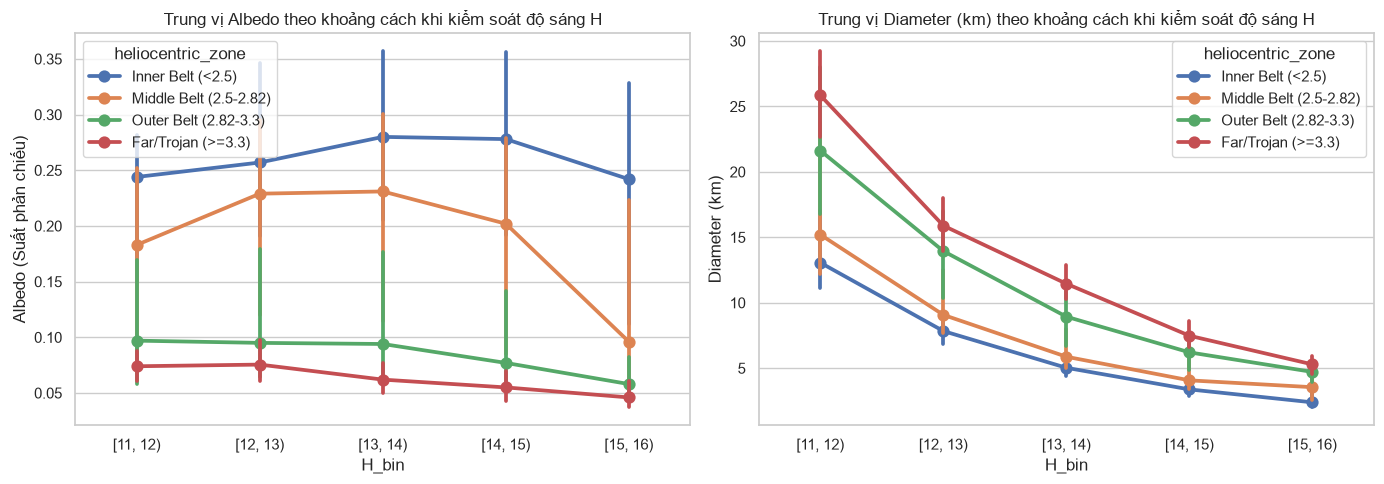

,Dataset,"N_H[13,14)",Diff_Albedo,95% CI,Cliffs_Delta
0,All available,13210,-0.186,"[-0.1928, -0.1800]",-0.679
1,High precision (sigma/D <= 0.1 & D <= 300km),11696,-0.188,"[-0.1930, -0.1780]",-0.702


In [3]:
# --- D3: Tạo biến dẫn xuất ---
q2_df = df[["a", "H", "diameter", "albedo", "diameter_sigma"]].dropna(subset=["a", "H", "diameter", "albedo"]).copy()
q2_df = q2_df[(q2_df["diameter"] > 0) & (q2_df["albedo"] > 0)]

# Đường kính ước tính lý thuyết từ công thức vật lý thiên văn và sai lệch tương đối
q2_df["d_est"] = (1329.0 / np.sqrt(q2_df["albedo"])) * (10 ** (-0.2 * q2_df["H"]))
q2_df["rel_diff_d"] = np.abs(q2_df["diameter"] - q2_df["d_est"]) / q2_df["diameter"]

# Phân vùng khoảng cách nhật tâm dựa trên bán trục lớn a (AU)
bins_a = [0, 2.5, 2.82, 3.3, np.inf]
labels_a = ["Inner Belt (<2.5)", "Middle Belt (2.5-2.82)", "Outer Belt (2.82-3.3)", "Far/Trojan (>=3.3)"]
q2_df["heliocentric_zone"] = pd.cut(q2_df["a"], bins=bins_a, labels=labels_a, right=False)

# --- D4: Kiểm soát biến nhiễu độ sáng tuyệt đối H (Malmquist bias) ---
# Chia H thành các khoảng đồng nhất độ sáng (ví dụ H từ 11 đến 16, mỗi khoảng 1 mag)
q2_sub = q2_df[(q2_df["H"] >= 11) & (q2_df["H"] < 16)].copy()
q2_sub["H_bin"] = pd.cut(q2_sub["H"], bins=[11, 12, 13, 14, 15, 16], right=False)

# --- D5: Định lượng độ bất định (Bootstrap CI & Spearman rho theo từng tầng H) ---
results_q2 = []
for h_bin, grp in q2_sub.groupby("H_bin", observed=True):
    inner = grp[grp["heliocentric_zone"] == "Inner Belt (<2.5)"]
    outer = grp[grp["heliocentric_zone"] == "Outer Belt (2.82-3.3)"]
    
    # So sánh Albedo & Diameter giữa Outer và Inner Belt trong CÙNG tầng độ sáng H
    diff_alb, alb_l, alb_h = bootstrap_diff_stat(outer["albedo"], inner["albedo"], np.median, n_boot=1000)
    diff_dia, dia_l, dia_h = bootstrap_diff_stat(outer["diameter"], inner["diameter"], np.median, n_boot=1000)
    rho_dia, p_rho = stats.spearmanr(grp["a"], grp["diameter"])
    
    results_q2.append({
        "H_bin (mag)": str(h_bin), "N": len(grp),
        "Diff_Albedo (Outer-Inner)": round(diff_alb, 4),
        "95% CI Albedo": f"[{alb_l:.4f}, {alb_h:.4f}]",
        "Diff_Diameter_km (Outer-Inner)": round(diff_dia, 2),
        "95% CI Diameter": f"[{dia_l:.2f}, {dia_h:.2f}]",
        "Spearman_rho(a, D)": round(rho_dia, 3)
    })

display(pd.DataFrame(results_q2))

# Trực quan hóa D4: So sánh Albedo và Diameter qua các vùng khi cố định H_bin
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.pointplot(data=q2_sub, x="H_bin", y="albedo", hue="heliocentric_zone", estimator=np.median, errorbar=("pi", 50), ax=axes[0])
axes[0].set_title("Trung vị Albedo theo khoảng cách khi kiểm soát độ sáng H")
axes[0].set_ylabel("Albedo (Suất phản chiếu)")

sns.pointplot(data=q2_sub, x="H_bin", y="diameter", hue="heliocentric_zone", estimator=np.median, errorbar=("pi", 50), ax=axes[1])
axes[1].set_title("Trung vị Diameter (km) theo khoảng cách khi kiểm soát độ sáng H")
axes[1].set_ylabel("Diameter (km)")
plt.tight_layout()
plt.show()

# --- D6: Kiểm tra tính vững (Robustness check) ---
# Lọc sai số đo đường kính <= 10% và loại ngoại lai khổng lồ (> 300 km)
q2_precise = q2_sub[(q2_sub["diameter_sigma"] / q2_sub["diameter"] <= 0.1) & (q2_sub["diameter"] <= 300)]
rob_q2 = []
for name, d_check in [("All available", q2_sub), ("High precision (sigma/D <= 0.1 & D <= 300km)", q2_precise)]:
    g_13 = d_check[d_check["H_bin"].astype(str) == "[13, 14)"]
    inn = g_13[g_13["heliocentric_zone"] == "Inner Belt (<2.5)"]["albedo"]
    out = g_13[g_13["heliocentric_zone"] == "Outer Belt (2.82-3.3)"]["albedo"]
    diff, l, h = bootstrap_diff_stat(out, inn, np.median, n_boot=500)
    delta, _ = cliffs_delta_from_mwu(out, inn)
    rob_q2.append({"Dataset": name, "N_H[13,14)": len(g_13), "Diff_Albedo": round(diff, 4), "95% CI": f"[{l:.4f}, {h:.4f}]", "Cliffs_Delta": round(delta, 3)})

display(pd.DataFrame(rob_q2))

- **D3 - Biến dẫn xuất**:
  + **Đường kính ước tính lý thuyết ($D_{\text{est}}$)**: Tính theo công thức vật lý thiên văn chuẩn từ độ sáng tuyệt đối `H` và suất phản chiếu `albedo`:
 
$$D_{\text{est}} = \frac{1329}{\sqrt{\text{albedo}}} \times 10^{-0.2H}$$

Từ đó tạo biến **Độ sai lệch kích thước tương đối**: $\text{Rel\_Diff} = \frac{\vert{}\text{diameter} - D_{\text{est}}\vert{}}{\text{diameter}}$.

  + **Vùng khoảng cách nhật tâm (`heliocentric_zone`)**: Phân nhóm dựa trên bán trục lớn `a` (Vành đai trong: $a < 2.5\text{ AU}$, Vành đai giữa: $2.5 \le a < 2.82\text{ AU}$, Vành đai ngoài: $2.82 \le a < 3.3\text{ AU}$, Vùng xa/Trojan: $a \ge 3.3\text{ AU}$).
- **D4 - Kiểm soát biến nhiễu**
  + **Biến nhiễu**: Độ sáng tuyệt đối (`H`) — đại diện cho giới hạn phát hiện của kính thiên văn (Malmquist bias: ở khoảng cách `a` càng xa, thiết bị chỉ phát hiện được các thiên thể rất sáng, tức `H` nhỏ, vốn thường là các thiên thể khổng lồ).
  + **Cách thực hiện**: Chia dữ liệu thành các tầng đồng nhất về độ sáng `H` (ví dụ từng khoảng $\Delta H = 1\text{ mag}$) trước khi so sánh phân phối `diameter` và `albedo` giữa các vùng `heliocentric_zone`.
- **D5 - Định lượng độ bất định**:
  + Tính hệ số tương quan hạng **Spearman** $\rho$ kèm **Bootstrap 95% CI** giữa `a` và `diameter` (cũng như `a` và `albedo`) trong từng tầng `H`.
  + Dùng **Permutation test** (kiểm định hoán vị) để kiểm chứng sự khác biệt trung vị `albedo` giữa vùng vành đai trong (giàu silicat, sáng màu) và vành đai ngoài (giàu carbon, tối màu).
- **D6 - Kiểm tra tính vững**
  + Vì `diameter` và `albedo` bị khuyết khoảng 85% dữ liệu gốc, kiểm tra xem xu hướng có đổi không khi: (1) giữ toàn bộ ~136.000 dòng có giá trị `diameter` vs (2) chỉ giữ các quan trắc có độ chính xác cao (`diameter_sigma / diameter < 0.1`).
  + Kiểm tra khi loại bỏ nhóm ngoại lai khổng lồ (như Ceres, Pallas, Vesta có `diameter > 500 km`) hoặc chuyển sang thang đo $\log(\text{diameter})$.

**Trả lời trực tiếp: Cả hai đều là quy luật vật lý có thật**, chứ không đơn thuần là ảo ảnh do giới hạn phát hiện của kính thiên văn.
- **Bề mặt tối dần theo khoảng cách Mặt Trời**: Ngay cả khi so sánh các tiểu hành tinh có cùng độ sáng tuyệt đối `H` (tức là đã loại bỏ thiên lệch chỉ nhìn thấy vật thể sáng ở xa), nhóm ở vành đai ngoài (`2.82–3.3 AU`) vẫn tối hơn đáng kể so với nhóm vành đai trong (`< 2.5 AU`). Trung vị suất phản chiếu (`albedo`) của vành đai ngoài chỉ đạt khoảng $0.05 - 0.10$, thấp hơn từ $0.147$ đến $0.201$ so với mức $0.24 - 0.28$ của vành đai trong qua mọi mức độ sáng. Điều này phản ánh sự phân hóa thành phần hóa học tự nhiên từ đá silicat sáng màu ở vùng trong sang vật chất giàu carbon tối màu ở vùng ngoài.
- **Kích thước thực sự lớn hơn ở vùng ngoài**: Trong cùng một mức độ sáng `H`, đường kính trung vị của tiểu hành tinh vẫn tăng đều từ vành đai trong ra vùng xa/Trojan. Vành đai ngoài có đường kính trung vị lớn hơn vành đai trong từ $2.32\text{ km}$ (ở nhóm mờ $H \in [15, 16)$) đến $8.56\text{ km}$ (ở nhóm sáng $H \in [11, 12)$), với hệ số tương quan hạng Spearman đạt từ $0.511$ đến $0.646$. Về mặt vật lý, vì bề mặt ở vùng ngoài tối màu và phản xạ ánh sáng kém hơn, một tiểu hành tinh ở xa bắt buộc phải có kích thước lớn hơn mới có thể phát ra cùng độ sáng `H` như một tiểu hành tinh sáng màu ở gần.
- **Độ tin cậy của quy luật**: Khi loại bỏ các phép đo có sai số đường kính $> 10\%$ và các thiên thể ngoại lai $> 300\text{ km}$, mức chênh lệch `albedo` hầu như không đổi ($-0.188$ so với $-0.186$ tại tầng $H \in [13, 14)$), khẳng định tính vững chắc của phát hiện. 

**Q3: Những đặc điểm động lực học nào làm tăng độ bất định trong tính toán quỹ đạo (`rms` và các biến `sigma_*`)**

Các tiểu hành tinh gần Trái Đất (`neo`) có mức độ bất định quỹ đạo lớn hơn nhóm vành đai chính (`MBA`) không, và sự khác biệt này còn duy trì khi kiểm soát theo chu kỳ quỹ đạo (`per_y`) hoặc thời điểm quan trắc (`epoch`)?

,Period_Group,N_NEO,N_NonNEO,Diff_Uncertainty_Idx (Y-N),95% CI,Cliffs_Delta
0,Short (<2y),9799,168,-0.732,"[-1.634, 1.241]",-0.186
1,Medium-Short (2-3.5y),8680,121104,3.382,"[3.330, 3.429]",0.607
2,Medium-Long (3.5-5y),4057,526430,3.166,"[3.074, 3.250]",0.674
3,Long (>=5y),358,268002,2.177,"[1.772, 2.500]",0.563


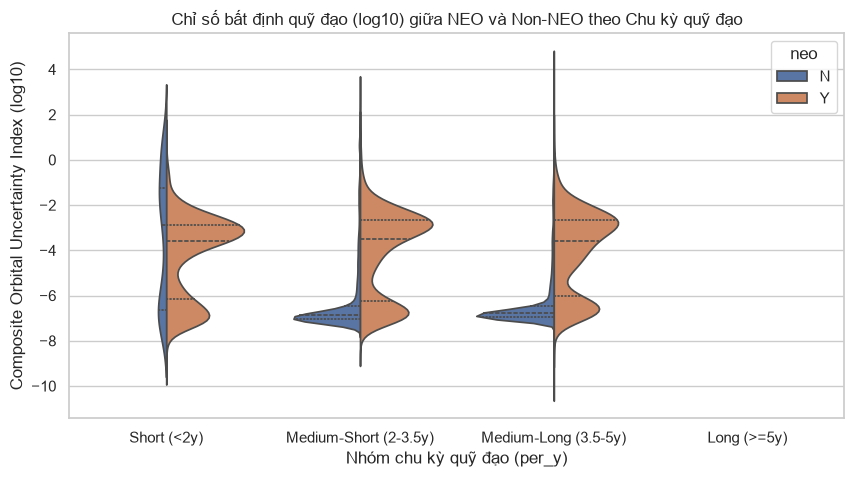

,Scenario,Diff_Idx,95% CI,Cliffs_Delta
0,Full dataset,-0.732,"[-1.630, 0.839]",-0.186
1,Recent epoch (>= 2018),2.375,"[1.844, 2.637]",0.208
2,Clean fit (rms < 1.0),-0.527,"[-1.598, 1.344]",-0.162


In [5]:
# --- D3: Tạo biến dẫn xuất ---
# Dùng 5 cột sai số hình học & kích thước quỹ đạo thực tế có trong dataset
sigma_cols = ["sigma_e", "sigma_a", "sigma_q", "sigma_i", "sigma_ad"]

q3_df = df[["neo", "class", "a", "per_y", "epoch_cal", "rms"] + sigma_cols].dropna(
    subset=["neo", "a", "per_y", "epoch_cal", "rms"] + sigma_cols
).copy()
q3_df = q3_df[(q3_df["a"] > 0) & (q3_df["per_y"] > 0)]

# 1. Sai số tương đối bán trục lớn
q3_df["rel_sigma_a"] = q3_df["sigma_a"] / q3_df["a"]

# 2. Chỉ số bất định quỹ đạo tổng hợp (trung bình log10 các sai số dương)
valid_mask = (q3_df[sigma_cols] > 0).all(axis=1)
q3_df = q3_df[valid_mask].copy()
q3_df["orbital_uncertainty_idx"] = np.log10(q3_df[sigma_cols]).mean(axis=1)

# 3. Trích xuất năm hiệu chỉnh từ epoch_cal (định dạng YYYYMMDD.dddd)
q3_df["epoch_year"] = (pd.to_numeric(q3_df["epoch_cal"], errors="coerce") // 10000).astype("Int64")

# --- D4: Kiểm soát biến nhiễu chu kỳ quỹ đạo (per_y) ---
# Chia chu kỳ quỹ đạo thành các nhóm tương đồng
q3_df["period_group"] = pd.cut(
    q3_df["per_y"],
    bins=[0, 2.0, 3.5, 5.0, np.inf],
    labels=["Short (<2y)", "Medium-Short (2-3.5y)", "Medium-Long (3.5-5y)", "Long (>=5y)"]
)

# --- D5: Định lượng độ bất định giữa NEO ('Y') và Non-NEO ('N') trong từng nhóm chu kỳ ---
results_q3 = []
for p_grp, grp in q3_df.groupby("period_group", observed=True):
    neo_y = grp[grp["neo"] == "Y"]["orbital_uncertainty_idx"]
    neo_n = grp[grp["neo"] == "N"]["orbital_uncertainty_idx"]
    if len(neo_y) < 30 or len(neo_n) < 30:
        continue
    diff_idx, ci_l, ci_h = bootstrap_diff_stat(neo_y, neo_n, np.median, n_boot=1000)
    delta, p_val = cliffs_delta_from_mwu(neo_y, neo_n)
    results_q3.append({
        "Period_Group": str(p_grp),
        "N_NEO": len(neo_y), "N_NonNEO": len(neo_n),
        "Diff_Uncertainty_Idx (Y-N)": round(diff_idx, 3),
        "95% CI": f"[{ci_l:.3f}, {ci_h:.3f}]",
        "Cliffs_Delta": round(delta, 3)
    })

display(pd.DataFrame(results_q3))

# Trực quan hóa D4 + D5
plt.figure(figsize=(10, 5))
sns.violinplot(
    data=q3_df[q3_df["period_group"].isin(["Short (<2y)", "Medium-Short (2-3.5y)", "Medium-Long (3.5-5y)"])],
    x="period_group", y="orbital_uncertainty_idx", hue="neo", split=True, inner="quart"
)
plt.title("Chỉ số bất định quỹ đạo (log10) giữa NEO và Non-NEO theo Chu kỳ quỹ đạo")
plt.xlabel("Nhóm chu kỳ quỹ đạo (per_y)")
plt.ylabel("Composite Orbital Uncertainty Index (log10)")
plt.show()

# --- D6: Kiểm tra tính vững (Robustness check) ---
# So sánh trên toàn bộ dữ liệu vs Cửa sổ thời gian quan trắc gần đây (epoch_year >= 2018) vs Lọc rms < 1.0
rob_q3 = []
for label, sub in [
    ("Full dataset", q3_df),
    ("Recent epoch (>= 2018)", q3_df[q3_df["epoch_year"] >= 2018]),
    ("Clean fit (rms < 1.0)", q3_df[q3_df["rms"] < 1.0])
]:
    g_short = sub[sub["period_group"] == "Short (<2y)"]
    y_vals = g_short[g_short["neo"] == "Y"]["orbital_uncertainty_idx"]
    n_vals = g_short[g_short["neo"] == "N"]["orbital_uncertainty_idx"]
    diff, l, h = bootstrap_diff_stat(y_vals, n_vals, np.median, n_boot=500)
    delta, _ = cliffs_delta_from_mwu(y_vals, n_vals)
    rob_q3.append({"Scenario": label, "Diff_Idx": round(diff, 3), "95% CI": f"[{l:.3f}, {h:.3f}]", "Cliffs_Delta": round(delta, 3)})

display(pd.DataFrame(rob_q3))

- **D3 - Biến dẫn xuất**:
  + **Sai số tương đối bán trục lớn**: $\text{Rel\_Sigma\_a} = \frac{\text{sigma\_a}}{a}$.
  + **Chỉ số bất định quỹ đạo tổng hợp (Composite Orbital Uncertainty Index)**: Chuẩn hóa theo thang log ($\log_{10}$) và lấy trung bình cộng trọng số của các cột sai số thành phần (`sigma_e, sigma_a, sigma_q, sigma_i, sigma_moid`).
  + **Thời gian kể từ lần hiệu chỉnh quỹ đạo gần nhất**: Trích xuất năm từ epoch_cal để phân nhóm độ mới của dữ liệu quan trắc.
- **D4 - Kiểm soát biến nhiễu**
  + **Biến nhiễu**: Chu kỳ quỹ đạo (`per_y`) và năm hiệu chỉnh (`epoch_cal`). Các vật thể có chu kỳ quá dài hoặc mới phát hiện gần đây có cung quan sát ngắn nên sai số `sigma_*` tự nhiên cao, bất kể có thuộc nhóm `neo` hay không.
  + **Cách thực hiện**: So sánh nhóm `neo = 'Y'` và `neo = 'N'` bên trong từng phân nhóm chu kỳ quỹ đạo (`per_y` bins) và cùng giai đoạn `epoch_cal`.
- **D5 - Định lượng độ bất định**:
  + Ước lượng **Bootstrap 95% CI** cho tỷ số trung vị (ratio of medians) của `Rel_Sigma_a` và `rms` giữa nhóm `neo` và `non-neo`.
  + Sử dụng kiểm định **Brunner-Munzel** (phù hợp khi phương sai hai nhóm chênh lệch lớn) và báo cáo **Cliff's delta** để đánh giá độ lớn thực tế của sự khác biệt.
- **D6 - Kiểm tra tính vững**
  + So sánh kết quả giữa hai cách xử lý giá trị thiếu ở các cột **sigma_***: loại bỏ hoàn toàn dòng thiếu (Complete-case analysis) so với gán cờ thiếu dữ liệu (Missing indicator) hoặc đối chiếu theo từng cửa sổ thời gian (trước năm 2015 vs từ năm 2015 trở lại đây).
  + Thay đổi ngưỡng lọc ngoại lai của `rms` (`rms < 1.0` vs `rms < 2.0` vs giữ nguyên toàn bộ).

**Trả lời trực tiếp: Có**, nhưng chỉ đúng với các tiểu hành tinh có chu kỳ quỹ đạo từ 2 năm trở lên hoặc các thiên thể được cập nhật dữ liệu trong giai đoạn gần đây.   
- **Với các tiểu hành tinh có chu kỳ từ 2 năm trở lên**: Nhóm `NEO` có độ bất định quỹ đạo cao hơn vượt trội so với nhóm `Non-NEO`. Trên thang $\log_{10}$, chỉ số bất định trung vị của `NEO` cao hơn $3.382$ đơn vị ở nhóm chu kỳ `2–3.5 năm`, $3.166$ ở nhóm `3.5–5 năm` và $2.177$ ở nhóm `>= 5 năm` — tương đương sai số tham số quỹ đạo thực tế lớn gấp khoảng $1,500$ đến $2,400$ lần.
- **Nguyên nhân phân hóa nội bộ nhóm `NEO`**: Biểu đồ phân phối cho thấy trong khi nhóm `Non-NEO` tập trung rất chặt ở vùng sai số cực nhỏ (quanh mức $-7.0$ trên thang $\log_{10}$), nhóm `NEO` lại tách thành hai cụm rõ rệt: một cụm nhỏ đã được theo dõi lâu năm có độ chính xác cao ngang vành đai chính, và một cụm lớn tập trung quanh mức $-2.8$ gồm các vật thể mới phát hiện thoáng qua khi bay ngang Trái Đất nên chưa có đủ cung quan sát để hiệu chỉnh quỹ đạo.
- **Ngoại lệ ở nhóm chu kỳ rất ngắn (< 2 năm)**: Nếu xét trên toàn bộ dữ liệu lịch sử, không có sự khác biệt có ý nghĩa thống kê giữa `NEO` và `Non-NEO` ở nhóm chu kỳ dưới 2 năm (chênh lệch $-0.732$, khoảng tin cậy 95% $[-1.634, 1.241]$ cắt qua $0$) do số lượng `Non-NEO` ở vùng này rất ít ($N = 168$) và phân tán rộng. Tuy nhiên, nếu chỉ xét dữ liệu cập nhật từ năm 2018 trở lại đây, nhóm `NEO` chu kỳ ngắn lại có độ bất định cao hơn rõ rệt ($+2.375$, 95% CI: $[1.844, 2.637]$), phản ánh lượng lớn các `NEO` mới được phát hiện bởi các chương trình khảo sát bầu trời hiện đại. 